<a href="https://colab.research.google.com/github/ljn11112/odometry3/blob/main/notebooks/wheel_separation_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Odometry Exercise 3 — plotting rotation data

Load a timestamped rotation log, plot the signed encoder counts and local odometry heading, and compare final reported rotation with your independent physical-angle measurements.

This notebook is an introduction to plotting odometry data. Start with the supplied synthetic example so that you can see what each cell produces. The example is not evidence about your robot. When you are ready, change the settings in the **Use your own data** cell and run the notebook again.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
rng = np.random.default_rng(2026)

## 1. Use the example or your own data

Leave `USE_EXAMPLE_DATA` set to `True` on your first run. To use your measurements, upload the CSV exported from the Serial Monitor, set `USE_EXAMPLE_DATA = False`, and enter its filename. This is the main cell you need to edit.


In [2]:
USE_EXAMPLE_DATA = False
CSV_FILENAME = "rotation_data.csv"

print("Using:", "synthetic example" if USE_EXAMPLE_DATA else CSV_FILENAME)

Using: rotation_data.csv


## 2. Create the small synthetic example

Run this cell when using the example. You do not need to understand or edit the generation code. Its columns match the rotation log in Exercise 3.


In [3]:
example_rows = []
example_conditions = [
    (1, np.pi / 2, 1.48, 2.0),
    (2, -np.pi / 2, -1.50, 1.5),
    (3, np.pi, 2.98, 3.0),
    (4, -np.pi, -3.01, 2.5),
]
for trial_num, command_rad, final_heading_rad, centre_motion_mm in example_conditions:
    for sample_num, progress in enumerate(np.linspace(0, 1, 31)):
        turn_sign = np.sign(final_heading_rad)
        wheel_count = progress * abs(final_heading_rad) * 170
        example_rows.append({
            "test_name": "rotation",
            "trial_num": trial_num,
            "commanded_angle_rad": command_rad,
            "sample_time_ms": 1000 * trial_num + 50 * sample_num,
            "left_encoder_count": round(-turn_sign * wheel_count),
            "right_encoder_count": round(turn_sign * wheel_count),
            "odometry_x_mm": centre_motion_mm * np.sin(np.pi * progress),
            "odometry_y_mm": centre_motion_mm * np.sin(2 * np.pi * progress) / 2,
            "odometry_theta_rad": progress * final_heading_rad,
        })

example_data = pd.DataFrame(example_rows)

## 3. Load and preview the selected data

When `USE_EXAMPLE_DATA` is false, `pd.read_csv(...)` reads your file. The final line displays its first five rows.


In [4]:
if USE_EXAMPLE_DATA:
    data = example_data.copy()
else:
    data = pd.read_csv(CSV_FILENAME)

data.head()

,test_name,trial_num,commanded_angle_rad,sample_time_ms,left_encoder_count,right_encoder_count,odometry_x_mm,odometry_y_mm,odometry_theta_rad
0,rotation5,1,6.2832,8330,0,1,0.14,0.00,0.00
1,rotation5,1,6.2832,8340,0,1,0.14,0.00,0.00
2,rotation5,1,6.2832,8350,0,1,0.14,0.00,0.00
3,rotation5,1,6.2832,8360,-2,2,0.00,-0.00,0.01
4,rotation5,1,6.2832,8370,-2,5,0.43,0.01,0.02


## 4. Calculate elapsed time

Subtract the first timestamp in each trial so that every plot begins at zero seconds. The heading is also converted to degrees for plotting.


In [5]:
data = data.loc[
    data["test_name"].isin([
        "rotation5",
        "rotation6",

    ])
].copy()

data = data.sort_values(["trial_num", "sample_time_ms"])

data["elapsed_s"] = (
    data["sample_time_ms"]
    - data.groupby("trial_num")["sample_time_ms"].transform("first")
) / 1000
data["heading_deg"] = np.degrees(data["odometry_theta_rad"])
data["trial_label"] = (
    data["test_name"] + " - Trial " + data["trial_num"].astype(str)
)
data[[
    "test_name",
    "trial_num",
    "sample_time_ms",
    "elapsed_s",
    "heading_deg"
]].head()

,test_name,trial_num,sample_time_ms,elapsed_s,heading_deg
0,rotation5,1,8330,0.00,0.000000
1,rotation5,1,8340,0.01,0.000000
2,rotation5,1,8350,0.02,0.000000
3,rotation5,1,8360,0.03,0.572958
4,rotation5,1,8370,0.04,1.145916


## 5. Plot both encoder counts

An in-place rotation should produce encoder-count changes with opposite signs. The plot lets you see how the two recorded count sequences developed during each turn.


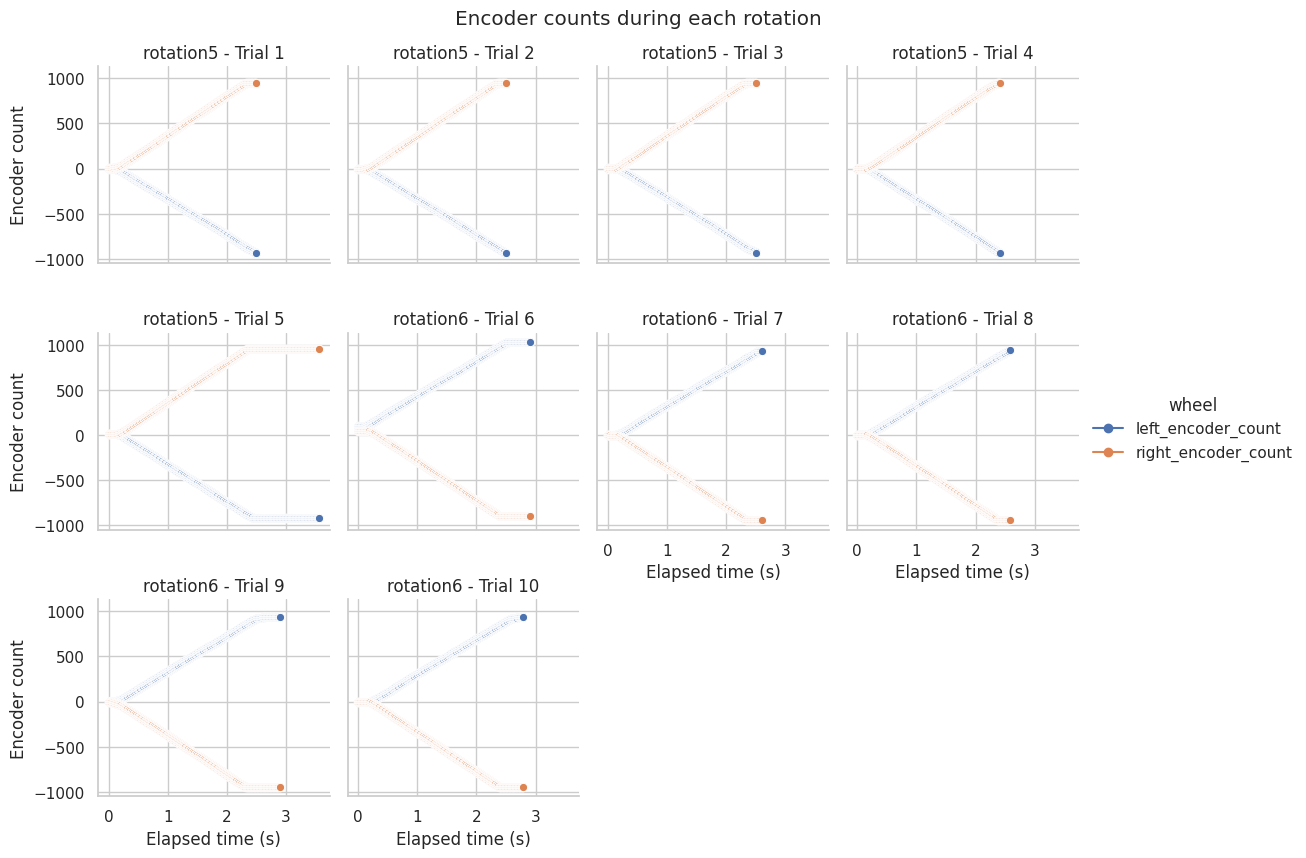

In [6]:
encoder_plot_data = data.melt(
    id_vars=["trial_num", "trial_label", "elapsed_s"],
    value_vars=["left_encoder_count", "right_encoder_count"],
    var_name="wheel",
    value_name="encoder_count",
)
grid = sns.relplot(
    data=encoder_plot_data,
    x="elapsed_s",
    y="encoder_count",
    hue="wheel",
    col="trial_label",
    col_wrap=4,
    kind="line",
    marker="o",
    estimator=None,
    height=2.8,
)
grid.set_axis_labels("Elapsed time (s)", "Encoder count")
grid.set_titles("{col_name}")
grid.figure.suptitle(
    "Encoder counts during each rotation",
    y=1.02
)

plt.show()

## 6. Plot the reported heading

This plot shows the heading accumulated by the local odometry model. It does not show the independently measured physical rotation.


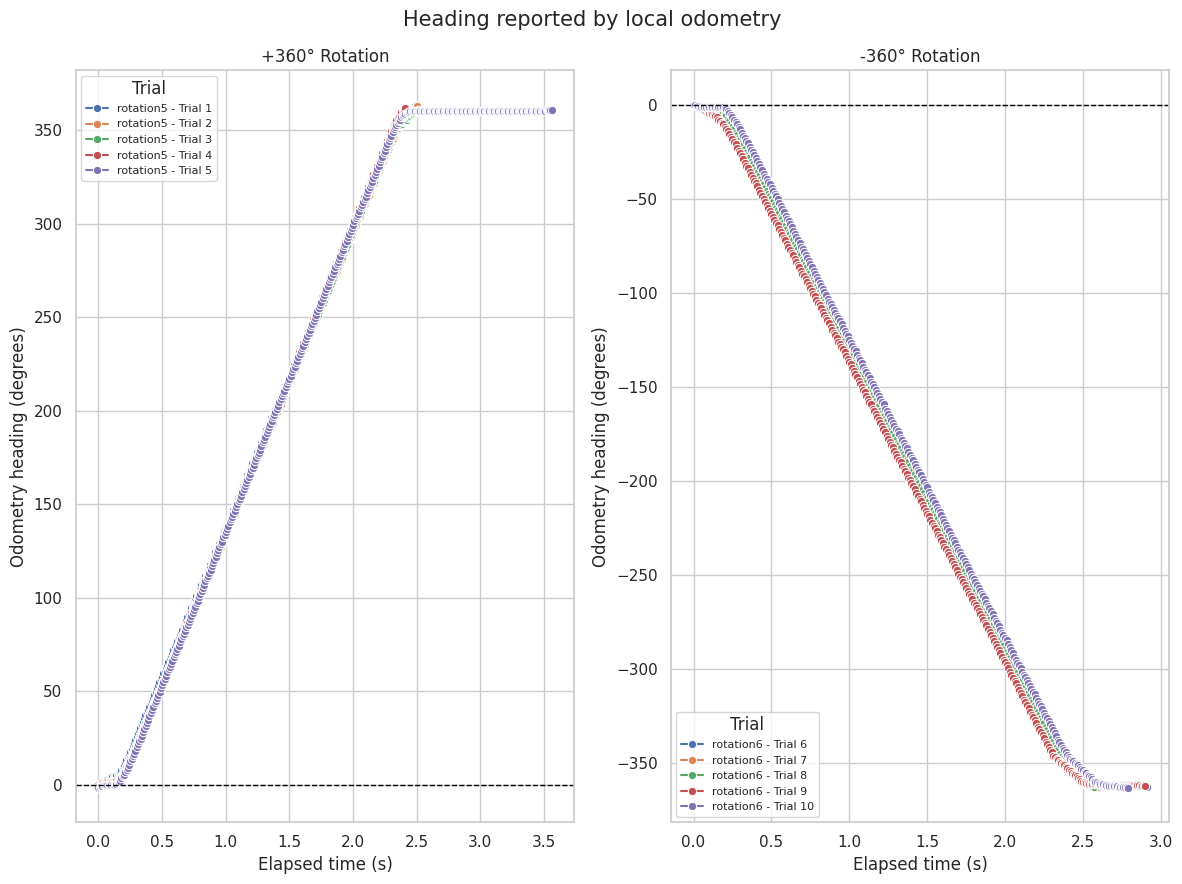

In [10]:
fig, axes = plt.subplots(1,2, figsize=(12, 9))
conditions = ["rotation5", "rotation6"]
titles = ["+360° Rotation", "-360° Rotation",
          ]

for ax, condition, title in zip(axes.flat, conditions, titles):
    subset = data[data["test_name"] == condition]

    sns.lineplot(
        data=subset,
        x="elapsed_s",
        y="heading_deg",
        hue="trial_label",
        marker="o",
        estimator=None,
        ax=ax,
    )

    ax.axhline(0, color="black", linewidth=1, linestyle="--")
    ax.set(
        title=title,
        xlabel="Elapsed time (s)",
        ylabel="Odometry heading (degrees)",
    )
    ax.legend(title="Trial", fontsize=8)

plt.suptitle("Heading reported by local odometry", fontsize=15)
plt.tight_layout()
plt.show()


## 7. Plot reported movement of the robot centre

For an ideal rotation on the spot, x and y would remain unchanged. This is still only the local model's report, so compare it with what you observed physically.


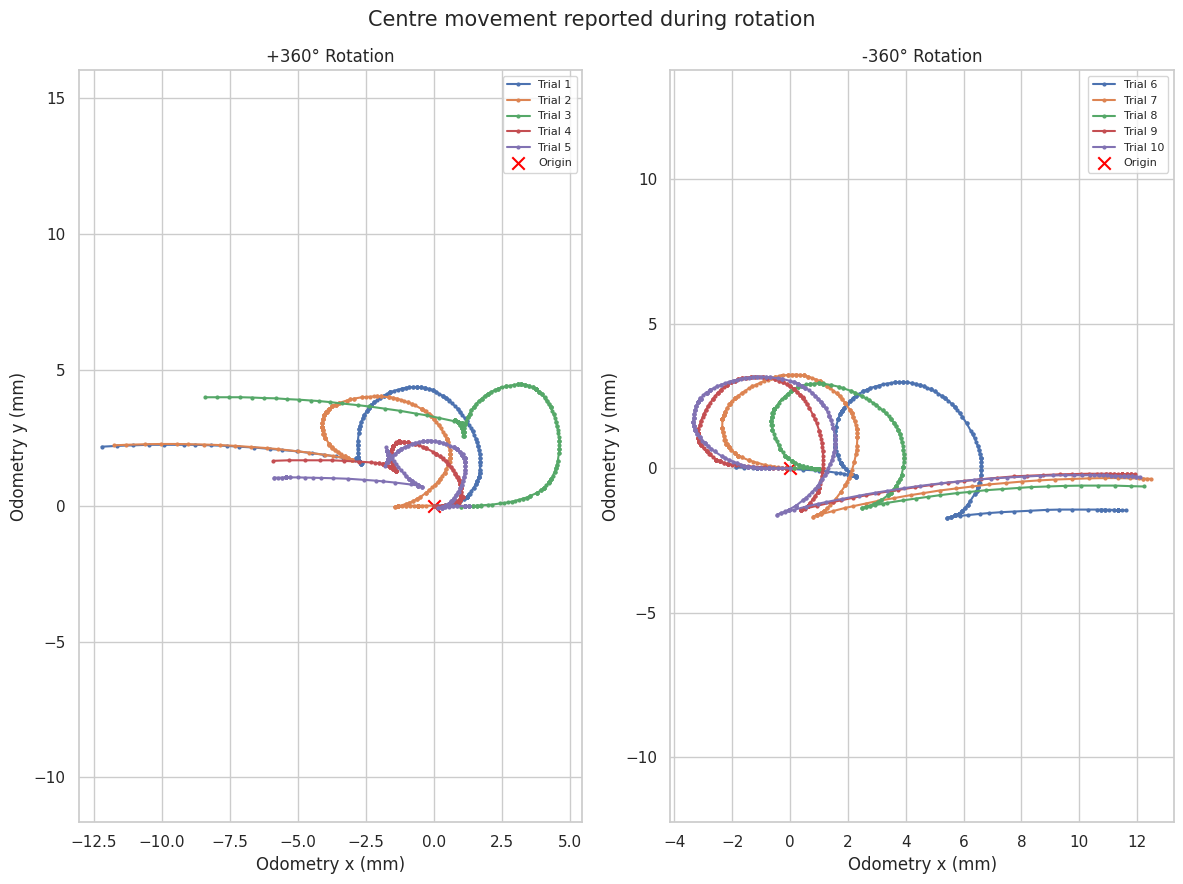

In [11]:
fig, axes = plt.subplots(1,2, figsize=(12, 9))
conditions = ["rotation5", "rotation6"]
titles = ["+360° Rotation", "-360° Rotation",
          ]
for ax, condition, title in zip(axes.flat, conditions, titles):
    subset = data[data["test_name"] == condition]
    for trial_num, trial_data in subset.groupby("trial_num"):
        trial_data = trial_data.sort_values("sample_time_ms")
        ax.plot(
            trial_data["odometry_x_mm"],
            trial_data["odometry_y_mm"],
            marker="o",
            markersize=2,
            linewidth=1.5,
            label=f"Trial {trial_num}"
        )
    ax.scatter(
        0, 0,
        color="red",
        marker="x",
        s=80,
        label="Origin"
    )

    ax.set(
        title=title,
        xlabel="Odometry x (mm)",
        ylabel="Odometry y (mm)"
    )
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(fontsize=8)

plt.suptitle(
    "Centre movement reported during rotation",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 8. Extract the initial and final reported headings

The following cell creates one row per trial and calculates the change between its first and final odometry headings and centre positions.


In [12]:
trial_summary = (
    data.sort_values(["trial_num", "sample_time_ms"])
    .groupby(["test_name", "trial_num"], as_index=False)
    .agg(
        commanded_angle_rad=("commanded_angle_rad", "first"),
        initial_x_mm=("odometry_x_mm", "first"),
        initial_y_mm=("odometry_y_mm", "first"),
        initial_heading_rad=("odometry_theta_rad", "first"),
        final_heading_rad=("odometry_theta_rad", "last"),
        final_x_mm=("odometry_x_mm", "last"),
        final_y_mm=("odometry_y_mm", "last"),
    )
)
trial_summary["reported_angle_rad"] = (
    trial_summary["final_heading_rad"]
    - trial_summary["initial_heading_rad"]
)

trial_summary["reported_angle_deg"] = np.degrees(
    trial_summary["reported_angle_rad"]
)
trial_summary["commanded_angle_deg"] = np.degrees(
    trial_summary["commanded_angle_rad"]
)

trial_summary["reported_centre_change_x_mm"] = (
    trial_summary["final_x_mm"]
    - trial_summary["initial_x_mm"]
)

trial_summary["reported_centre_change_y_mm"] = (
    trial_summary["final_y_mm"]
    - trial_summary["initial_y_mm"]
)

trial_summary["centre_displacement_mm"] = np.sqrt(
    trial_summary["reported_centre_change_x_mm"]**2
    + trial_summary["reported_centre_change_y_mm"]**2
)

trial_summary[[
    "test_name",
    "trial_num",
    "commanded_angle_deg",
    "reported_angle_deg",
    "reported_centre_change_x_mm",
    "reported_centre_change_y_mm",
    "centre_displacement_mm"
]]

,test_name,trial_num,commanded_angle_deg,reported_angle_deg,reported_centre_change_x_mm,reported_centre_change_y_mm,centre_displacement_mm
0,rotation5,1,360.000842,363.828200,-12.36,2.17,12.549044
1,rotation5,2,360.000842,363.255242,-11.76,2.22,11.967707
2,rotation5,3,360.000842,362.682284,-9.55,4.00,10.353864
3,rotation5,4,360.000842,362.109327,-5.90,1.65,6.126377
4,rotation5,5,360.000842,362.109327,-6.46,1.03,6.541598
5,rotation6,6,-360.000842,-362.682284,13.49,-1.49,13.572037
6,rotation6,7,-360.000842,-362.682284,12.49,-0.37,12.495479
7,rotation6,8,-360.000842,-362.682284,12.24,-0.63,12.256203
8,rotation6,9,-360.000842,-362.109327,12.06,-0.21,12.061828
9,rotation6,10,-360.000842,-363.255242,12.12,-0.30,12.123712


## 9. Enter your physical angle measurements

The robot log does not contain the angle you measured on the printed sheet. Enter the independently measured start and final headings below in degrees. Use the same positive and negative convention as the odometry. Add or remove rows so that the trial numbers match your log. Record the radius and separation used by the model during each trial, and label the row as `calibration` or `held-back`.


In [16]:
physical_measurements = pd.DataFrame({
    "trial_num": list(range(1, 11)),
    "measured_start_heading_deg": [0.0] * 10,
    "measured_final_heading_deg": [
        362, 363, 362, 362, 363,
        -361, -362, -362, -361, -362
    ],
    "model_wheel_radius_mm": [16.425] * 10,
    "model_wheel_separation_mm": [85.64] * 10,
    "surface": ["test surface"] * 10,
    "data_use": ["validation"] * 10
})

comparison = trial_summary.merge(
    physical_measurements,
    on="trial_num",
    how="inner",
    validate="one_to_one"
)

comparison["measured_angle_deg"] = (
    comparison["measured_final_heading_deg"]
    - comparison["measured_start_heading_deg"]
)

comparison["angle_error_deg"] = (
    comparison["reported_angle_deg"]
    - comparison["measured_angle_deg"]
)

comparison["absolute_error_deg"] = (
    comparison["angle_error_deg"].abs()
)

display(comparison[[
    "trial_num",
    "measured_angle_deg",
    "reported_angle_deg",
    "angle_error_deg",
    "absolute_error_deg",
    "data_use"
]])

,trial_num,measured_angle_deg,reported_angle_deg,angle_error_deg,absolute_error_deg,data_use
0,1,362.0,363.828200,1.828200,1.828200,validation
1,2,363.0,363.255242,0.255242,0.255242,validation
2,3,362.0,362.682284,0.682284,0.682284,validation
3,4,362.0,362.109327,0.109327,0.109327,validation
4,5,363.0,362.109327,-0.890673,0.890673,validation
5,6,-361.0,-362.682284,-1.682284,1.682284,validation
6,7,-362.0,-362.682284,-0.682284,0.682284,validation
7,8,-362.0,-362.682284,-0.682284,0.682284,validation
8,9,-361.0,-362.109327,-1.109327,1.109327,validation
9,10,-362.0,-363.255242,-1.255242,1.255242,validation


## 10. Calculate a separation estimate for each calibration trial

Exercise 3 gives the calculation `new separation = old separation × reported angle ÷ measured angle`. The cell applies it only to rows you labelled `calibration`, then shows the individual estimates together with their mean and median.


In [18]:

validation = comparison[
    comparison["data_use"] == "validation"
].copy()

# Calculate absolute percentage error
validation["APE_percent"] = (
    validation["absolute_error_deg"]
    / validation["measured_angle_deg"].abs()
) * 100

# Overall validation metrics
mae = validation["absolute_error_deg"].mean()

rmse = np.sqrt(
    np.mean(validation["angle_error_deg"] ** 2)
)

mape = validation["APE_percent"].mean()

print(f"Validation MAE: {mae:.2f} degrees")
print(f"Validation RMSE: {rmse:.2f} degrees")
print(f"Validation MAPE: {mape:.2f}%")

# Separate clockwise and counterclockwise
validation["direction"] = np.where(
    validation["measured_angle_deg"] > 0,
    "360°, counterclockwise",
    "360°, clockwise"
)

summary = validation.groupby("direction").agg(
    MAE_deg=("absolute_error_deg", "mean"),
    MAPE_percent=("APE_percent", "mean")
).reset_index()

print("\nValidation results by direction:")
display(summary.round(2))


Validation MAE: 0.92 degrees
Validation RMSE: 1.06 degrees
Validation MAPE: 0.25%

Validation results by direction:


,direction,MAE_deg,MAPE_percent
0,"360°, clockwise",1.08,0.30
1,"360°, counterclockwise",0.75,0.21


## 11. Plot measured rotation against reported rotation

Points on the dashed line indicate agreement. A consistent offset from the line suggests that the wheel-separation value used by the local model may need adjustment. Keep the held-back row out of the separation estimate and use it later to evaluate the selected value.


## What to notice

- Do the two encoder counts change with opposite signs?
- Does the odometry heading change smoothly during each turn?
- Does the reported angle tend to be larger or smaller than the physical measurement?

Save the notebook with your plots. Base conclusions about physical rotation on your independent measurements, not on the commanded angle.
